# Task-1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import roc_auc_score

In [2]:
# 1. Generate 1,000 strongly correlated data points
np.random.seed(42)

x = np.random.normal(0, 1, 1000)
y = x + np.random.normal(0, 0.15, 1000)

normal_data = pd.DataFrame({
    "Feature_1": x,
    "Feature_2": y
})

In [3]:
# 2. Inject 5 anomalies that break the correlation
anomalies = np.array([
    [2, -2],
    [-2, 2],
    [2.2, -2.2],
    [-2.2, 2.2],
    [2.5, -2.5]
])

anomaly_data = pd.DataFrame(
    anomalies,
    columns=["Feature_1", "Feature_2"]
)

# Combine normal data and anomalies
data = pd.concat(
    [normal_data, anomaly_data],
    ignore_index=True
)

# Mark the injected anomalies
data["is_anomaly"] = False
data.loc[1000:, "is_anomaly"] = True

In [4]:
# 3. Calculate absolute z-scores for each feature
features = ["Feature_1", "Feature_2"]

z_scores = (
    (data[features] - data[features].mean())
    / data[features].std()
).abs()

# Maximum absolute z-score for each point
data["max_abs_z_score"] = z_scores.max(axis=1)

# Display the 5 injected anomalies and their z-scores
print("Maximum absolute z-score for each injected anomaly:")
print(
    data.loc[1000:, ["Feature_1", "Feature_2", "max_abs_z_score"]]
)

Maximum absolute z-score for each injected anomaly:
      Feature_1  Feature_2  max_abs_z_score
1000        2.0       -2.0         2.039012
1001       -2.0        2.0         2.044521
1002        2.2       -2.2         2.240166
1003       -2.2        2.2         2.246776
1004        2.5       -2.5         2.541896


In [5]:
# 4. Check how many anomalies appear in the top 5
top_5_zscore = data.nlargest(5, "max_abs_z_score")

caught = top_5_zscore["is_anomaly"].sum()

print("\nNumber of injected anomalies in the top 5:", caught)

print("\nTop 5 points according to z-score:")
print(
    top_5_zscore[
        ["Feature_1", "Feature_2", "is_anomaly", "max_abs_z_score"]
    ]
)


Number of injected anomalies in the top 5: 0

Top 5 points according to z-score:
     Feature_1  Feature_2  is_anomaly  max_abs_z_score
209   3.852731   4.115168       False         4.111421
262  -3.241267  -3.160454       False         3.299785
478   3.078881   2.945757       False         3.091631
755   2.632382   2.838431       False         2.827321
646  -2.696887  -2.724958       False         2.768151


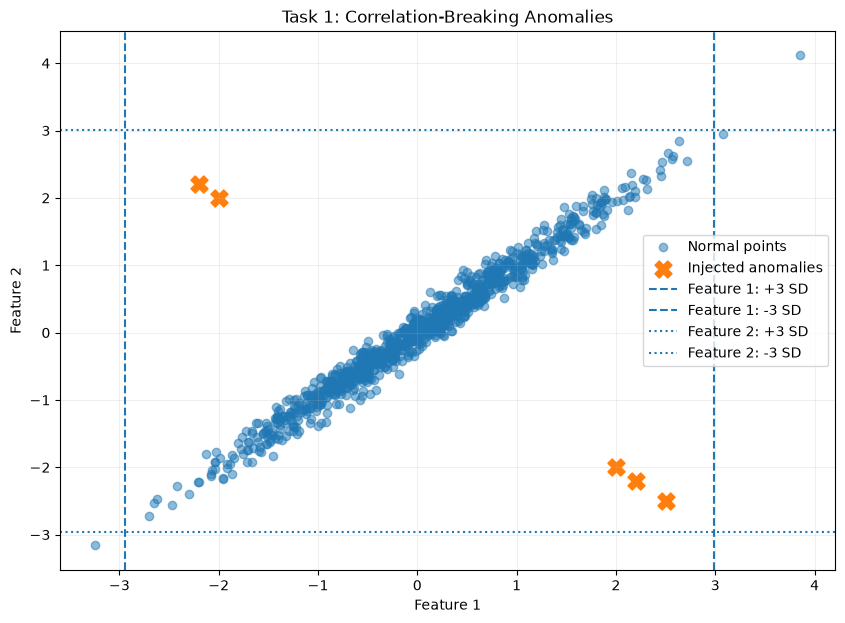

In [6]:
# 5. Draw the plot and ±3 standard deviation limits
fig, ax = plt.subplots(figsize=(10, 7))

normal_points = data[~data["is_anomaly"]]
anomaly_points = data[data["is_anomaly"]]

ax.scatter(
    normal_points["Feature_1"],
    normal_points["Feature_2"],
    alpha=0.5,
    label="Normal points"
)

ax.scatter(
    anomaly_points["Feature_1"],
    anomaly_points["Feature_2"],
    marker="X",
    s=150,
    label="Injected anomalies"
)

# Calculate ±3 standard deviation limits for each feature
mean_values = data[features].mean()
std_values = data[features].std()

ax.axvline(
    mean_values["Feature_1"] + 3 * std_values["Feature_1"],
    linestyle="--",
    label="Feature 1: +3 SD"
)

ax.axvline(
    mean_values["Feature_1"] - 3 * std_values["Feature_1"],
    linestyle="--",
    label="Feature 1: -3 SD"
)

ax.axhline(
    mean_values["Feature_2"] + 3 * std_values["Feature_2"],
    linestyle=":",
    label="Feature 2: +3 SD"
)

ax.axhline(
    mean_values["Feature_2"] - 3 * std_values["Feature_2"],
    linestyle=":",
    label="Feature 2: -3 SD"
)

ax.set_title("Task 1: Correlation-Breaking Anomalies")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

**Conclusion:**

A point can be ordinary in every individual feature but still be anomalous because it violates the expected relationship between the features. Per-feature z-scores may fail to detect such points because they evaluate each feature independently rather than considering the relationship between them.

A real-world example is an insurance claim where the individual values appear normal, but the combination of claim characteristics is inconsistent with the usual pattern.

# Task-2

In [7]:
# 1. Implement an IQR-based detector
features = ["Feature_1", "Feature_2"]

def iqr_detector(df, columns):
    flags = pd.DataFrame(False, index=df.index, columns=columns)
    fences = {}

    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        flags[col] = (df[col] < lower) | (df[col] > upper)
        fences[col] = {
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower Fence": lower,
            "Upper Fence": upper
        }

    # Score each point by the number of flagged features
    scores = flags.sum(axis=1)

    return scores, fences

In [8]:
# 2. Run IQR on the original Task 1 data
iqr_scores, original_fences = iqr_detector(data, features)

original_data = data.copy()
original_data["iqr_score"] = iqr_scores

original_caught = original_data.loc[1000:, "iqr_score"].gt(0).sum()

print("IQR results on original data")
print("Injected anomalies caught:", original_caught, "out of 5")
print("\nOriginal IQR fences:")
print(pd.DataFrame(original_fences).T)

IQR results on original data
Injected anomalies caught: 0 out of 5

Original IQR fences:
                 Q1        Q3       IQR  Lower Fence  Upper Fence
Feature_1 -0.650643  0.650201  1.300844    -2.601908     2.601467
Feature_2 -0.648357  0.683100  1.331457    -2.645543     2.680286


In [9]:
# 3. Record original standard deviation and z-scores
original_std = data["Feature_1"].std()

original_anomaly_z = (
    (data.loc[1000:, "Feature_1"] - data["Feature_1"].mean())
    / original_std
).abs()

print("\nOriginal Feature_1 standard deviation:", original_std)
print("Original anomaly absolute z-scores:")
print(original_anomaly_z.to_list())


Original Feature_1 standard deviation: 0.988849411263618
Original anomaly absolute z-scores:
[2.000584253615367, 2.0445210520433905, 2.2028395188983048, 2.246776317326329, 2.5062224168227116]


In [10]:
# 4. Add 50 extreme outliers to Feature_1
data_with_outliers = data.copy()

extreme_outliers = pd.DataFrame({
    "Feature_1": np.full(50, 20.0),
    "Feature_2": np.zeros(50),
    "is_anomaly": False
})

data_with_outliers = pd.concat(
    [data_with_outliers, extreme_outliers],
    ignore_index=True
)

In [11]:
# 5. Re-run z-score on the modified data
new_mean = data_with_outliers["Feature_1"].mean()
new_std = data_with_outliers["Feature_1"].std()

data_with_outliers["z_score_feature_1"] = (
    (data_with_outliers["Feature_1"] - new_mean) / new_std
).abs()

# Count the five injected anomalies in the top 5
top5_after_z = data_with_outliers.nlargest(5, "z_score_feature_1")
z_caught_after = top5_after_z["is_anomaly"].sum()

In [12]:
# 6. Re-run IQR on the modified data
new_iqr_scores, new_fences = iqr_detector(
    data_with_outliers, features
)

data_with_outliers["iqr_score"] = new_iqr_scores

iqr_caught_after = (
    data_with_outliers.loc[1000:1004, "iqr_score"].gt(0).sum()
)

In [13]:
# 7. Calculate the five anomalies' new z-scores
new_anomaly_z = data_with_outliers.loc[
    1000:1004, "z_score_feature_1"
]

print("\n--- Comparison After Adding 50 Extreme Outliers ---")
print("Original standard deviation:", original_std)
print("New standard deviation:", new_std)

print("\nOriginal anomaly absolute z-scores:")
print(original_anomaly_z.to_list())

print("\nNew anomaly absolute z-scores:")
print(new_anomaly_z.to_list())

print("\nIQR anomalies caught before adding outliers:",
      original_caught, "out of 5")

print("IQR anomalies caught after adding outliers:",
      iqr_caught_after, "out of 5")

print("\nZ-score anomalies in the top 5 after adding outliers:",
      z_caught_after, "out of 5")

print("\nNew IQR fences:")
print(pd.DataFrame(new_fences).T)

print("\nTop 5 points after adding outliers:")
print(
    data_with_outliers.nlargest(5, "z_score_feature_1")[
        ["Feature_1", "Feature_2", "is_anomaly", "z_score_feature_1"]
    ]
)


--- Comparison After Adding 50 Extreme Outliers ---
Original standard deviation: 0.988849411263618
New standard deviation: 4.355251780322867

Original anomaly absolute z-scores:
[2.000584253615367, 2.0445210520433905, 2.2028395188983048, 2.246776317326329, 2.5062224168227116]

New anomaly absolute z-scores:
[0.236826448084391, 0.6816049542221523, 0.2827480181997182, 0.7275265243374796, 0.3516303733727089]

IQR anomalies caught before adding outliers: 0 out of 5
IQR anomalies caught after adding outliers: 1 out of 5

Z-score anomalies in the top 5 after adding outliers: 0 out of 5

New IQR fences:
                 Q1        Q3       IQR  Lower Fence  Upper Fence
Feature_1 -0.601173  0.763925  1.365097    -2.648819     2.811571
Feature_2 -0.613461  0.639656  1.253117    -2.493136     2.519331

Top 5 points after adding outliers:
      Feature_1  Feature_2  is_anomaly  z_score_feature_1
1005       20.0        0.0       False           4.369768
1006       20.0        0.0       False      

**Conclusion:**

The IQR method is more robust than the z-score method when extreme outliers are present because it uses quartiles, which are less affected by extreme values than the mean and standard deviation. After adding 50 extreme outliers, the standard deviation of Feature 1 increases, which can reduce the absolute z-scores of the injected anomalies, while the IQR fences generally remain more stable. This demonstrates that z-scores can become less effective when the data already contains extreme outliers. However, both methods can miss anomalies that break relationships between features while remaining within the individual feature boundaries.

# Task-3

In [14]:
# Features and evaluation labels
features = ["Feature_1", "Feature_2"]
X = data[features]
y_true = data["is_anomaly"].astype(int)

In [15]:
# 1. Z-score anomaly scores (from Task 1)
z_scores = (
    (X - X.mean()) / X.std()
).abs().max(axis=1)

In [16]:
# 2. Local Outlier Factor (LOF)
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto"
)

lof.fit_predict(X)

# Larger scores indicate more anomalous points
lof_scores = -lof.negative_outlier_factor_

In [17]:
# 3. Isolation Forest
isolation_forest = IsolationForest(
    random_state=42,
    contamination="auto"
)

isolation_forest.fit(X)

# Larger scores indicate more anomalous points
isolation_scores = -isolation_forest.score_samples(X)

In [18]:
# 4. Compare top-5 results and AUC
methods = {
    "Z-score": z_scores,
    "LOF": lof_scores,
    "Isolation Forest": isolation_scores
}

results = []

for method_name, scores in methods.items():

    # Identify the five highest anomaly scores
    top_5_indices = np.argsort(
        np.asarray(scores)
    )[-5:][::-1]

    # Count injected anomalies in the top five
    anomalies_caught = int(
        y_true.iloc[top_5_indices].sum()
    )

    # Calculate AUC using labels for evaluation only
    auc = roc_auc_score(y_true, scores)

    results.append({
        "Method": method_name,
        "Injected Anomalies in Top 5": anomalies_caught,
        "AUC": auc
    })

results_df = pd.DataFrame(results)

print("Task 3: Anomaly Detection Comparison")
print(results_df.to_string(index=False))

Task 3: Anomaly Detection Comparison
          Method  Injected Anomalies in Top 5    AUC
         Z-score                            0 0.9704
             LOF                            5 1.0000
Isolation Forest                            1 0.9916


In [19]:
# 5. Display the top five points for each method
for method_name, scores in methods.items():

    top_5_indices = np.argsort(
        np.asarray(scores)
    )[-5:][::-1]

    print(f"\n{method_name} — Top 5 Points:")

    print(
        data.iloc[top_5_indices][
            ["Feature_1", "Feature_2", "is_anomaly"]
        ].assign(
            anomaly_score=np.asarray(scores)[top_5_indices]
        ).to_string(index=True)
    )


Z-score — Top 5 Points:
     Feature_1  Feature_2  is_anomaly  anomaly_score
209   3.852731   4.115168       False       4.111421
262  -3.241267  -3.160454       False       3.299785
478   3.078881   2.945757       False       3.091631
755   2.632382   2.838431       False       2.827321
646  -2.696887  -2.724958       False       2.768151

LOF — Top 5 Points:
      Feature_1  Feature_2  is_anomaly  anomaly_score
1004        2.5       -2.5        True      20.824725
1003       -2.2        2.2        True      19.312910
1002        2.2       -2.2        True      18.936344
1000        2.0       -2.0        True      17.954446
1001       -2.0        2.0        True      17.633859

Isolation Forest — Top 5 Points:
      Feature_1  Feature_2  is_anomaly  anomaly_score
262   -3.241267  -3.160454       False       0.758609
209    3.852731   4.115168       False       0.757493
646   -2.696887  -2.724958       False       0.743996
668   -2.650970  -2.524877       False       0.737980
1004   2

**Conclusion:**

A high AUC can coexist with a poor top-5 result because AUC measures overall ranking quality, while the top-5 result measures how effectively a method identifies the most important anomalies at the top of its list. Therefore, anomaly detection methods should be evaluated using both AUC and top-of-list metrics because a high AUC alone does not guarantee a useful investigation queue.

In this experiment, LOF detected the correlation-breaking anomalies more effectively than z-score and Isolation Forest. Isolation Forest may struggle with these anomalies because it splits individual features along their axes rather than directly modelling the relationship between features.

# Task-4


--- PCA with 1 Component(s) ---
Mean reconstruction error (normal): 0.01117970
Mean reconstruction error (anomalies): 9.57738900
Anomalies in top 5: 5 out of 5
Explained variance ratio: [0.97008154]


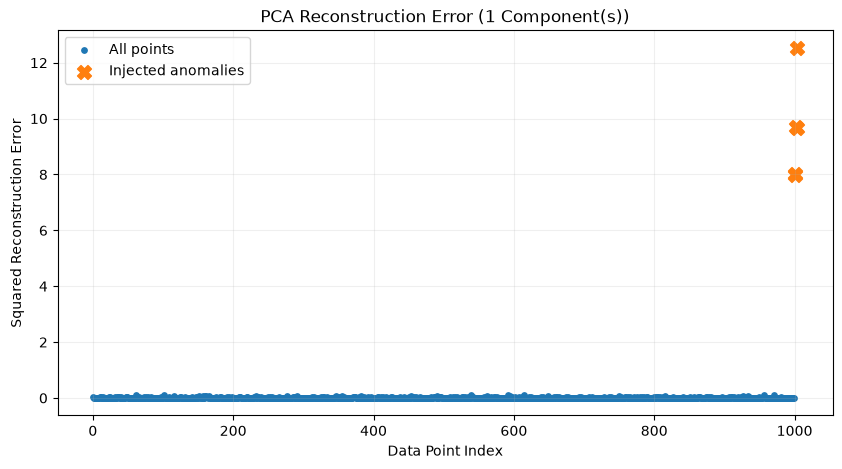


--- PCA with 2 Component(s) ---
Mean reconstruction error (normal): 0.00000000
Mean reconstruction error (anomalies): 0.00000000
Anomalies in top 5: 0 out of 5
Explained variance ratio: [0.97008154 0.02991846]


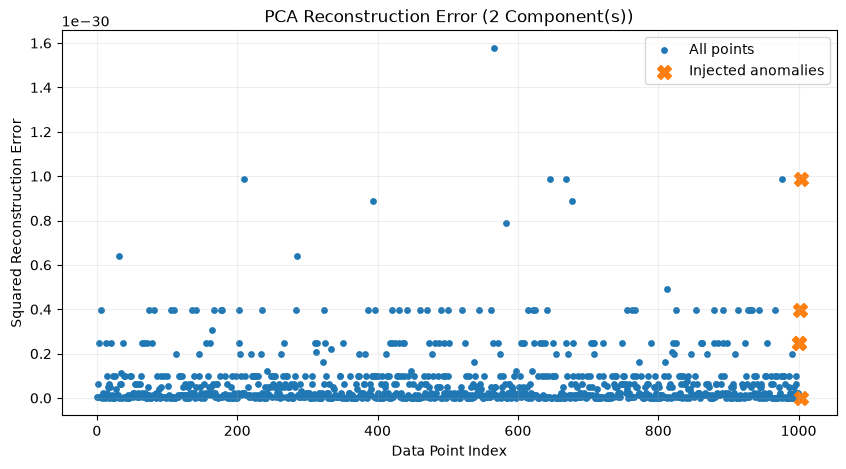

In [20]:
features = ["Feature_1", "Feature_2"]
X = data[features].to_numpy()
is_anomaly = data["is_anomaly"].to_numpy()

results = []

for n_components in [1, 2]:

    # Fit PCA and reconstruct the original data
    pca = PCA(n_components=n_components)
    X_transformed = pca.fit_transform(X)
    X_reconstructed = pca.inverse_transform(X_transformed)

    # Calculate squared reconstruction error per point
    reconstruction_error = np.sum(
        (X - X_reconstructed) ** 2,
        axis=1
    )

    # Separate normal points and injected anomalies
    normal_errors = reconstruction_error[~is_anomaly]
    anomaly_errors = reconstruction_error[is_anomaly]

    # Identify the five points with the highest error
    top_5_indices = np.argsort(reconstruction_error)[-5:][::-1]
    anomalies_in_top_5 = int(is_anomaly[top_5_indices].sum())

    results.append({
        "Components": n_components,
        "Mean Normal Error": normal_errors.mean(),
        "Mean Anomaly Error": anomaly_errors.mean(),
        "Anomalies in Top 5": anomalies_in_top_5
    })

    print(f"\n--- PCA with {n_components} Component(s) ---")
    print(f"Mean reconstruction error (normal): {normal_errors.mean():.8f}")
    print(f"Mean reconstruction error (anomalies): {anomaly_errors.mean():.8f}")
    print(f"Anomalies in top 5: {anomalies_in_top_5} out of 5")
    print(f"Explained variance ratio: {pca.explained_variance_ratio_}")

    # Plot reconstruction errors
    plt.figure(figsize=(10, 5))
    plt.scatter(
        np.arange(len(reconstruction_error)),
        reconstruction_error,
        s=15,
        label="All points"
    )
    plt.scatter(
        np.where(is_anomaly)[0],
        reconstruction_error[is_anomaly],
        marker="X",
        s=100,
        label="Injected anomalies"
    )
    plt.title(f"PCA Reconstruction Error ({n_components} Component(s))")
    plt.xlabel("Data Point Index")
    plt.ylabel("Squared Reconstruction Error")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

In [21]:
# Final comparison table
results_df = pd.DataFrame(results)
print("\n--- Task 4 Comparison ---")
print(results_df.to_string(index=False))


--- Task 4 Comparison ---
 Components  Mean Normal Error  Mean Anomaly Error  Anomalies in Top 5
          1       1.117970e-02        9.577389e+00                   5
          2       7.291530e-32        3.747089e-31                   0


PCA reconstruction error can help detect anomalies when normal data follows a consistent relationship that can be represented using a small number of principal components. In this experiment, using one component allows PCA to learn the main relationship between the two features, so points that break that relationship can have higher reconstruction errors.

Using two components retains both original dimensions, making reconstruction error approximately zero for all points. Therefore, selecting an appropriate number of components is important for anomaly detection.

# Task-5

In [22]:
df=pd.read_csv("insurance_claims.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (8000, 10)
Columns: ['claim_id', 'claim_amount', 'customer_tenure_months', 'age', 'prior_claims', 'days_to_report', 'policy_type', 'region', 'channel', 'is_fraud']


In [23]:
# 2. Separate labels from features

target_column = "is_fraud"

if target_column not in df.columns:
    raise ValueError("The dataset must contain an 'is_fraud' column.")

y = df[target_column].astype(int).reset_index(drop=True)

# Remove the target and identifier columns from model features
excluded_columns = [target_column]

if "claim_id" in df.columns:
    excluded_columns.append("claim_id")

X_raw = df.drop(columns=excluded_columns).copy()
X_raw = X_raw.reset_index(drop=True)

if y.nunique() != 2:
    raise ValueError("is_fraud must contain both 0 and 1.")

In [24]:
# 3. Handle missing values and encode categories

numeric_columns = X_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

# Fill missing numerical values with their medians
for col in numeric_columns:
    X_raw[col] = X_raw[col].fillna(X_raw[col].median())

# Fill missing categorical values with the most common value
for col in categorical_columns:
    mode_values = X_raw[col].mode(dropna=True)

    fill_value = (
        mode_values.iloc[0]
        if not mode_values.empty
        else "Unknown"
    )

    X_raw[col] = X_raw[col].fillna(fill_value).astype(str)

# One-hot encode categorical features
X_encoded = pd.get_dummies(
    X_raw,
    columns=categorical_columns,
    dtype=int
)

# Scale every feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

print("\nPrepared feature shape:", X_scaled.shape)


Prepared feature shape: (8000, 15)


In [25]:
# 4. Report the fraud-rate baseline

fraud_rate = y.mean()

print(f"\nTotal claims: {len(y):,}")
print(f"Fraudulent claims: {y.sum():,}")
print(f"Fraud rate baseline: {fraud_rate:.4%}")


Total claims: 8,000
Fraudulent claims: 295
Fraud rate baseline: 3.6875%


In [26]:
# 5. Define Precision@K

def precision_at_k(y_true, scores, k):
    """
    Fraction of the top k highest-scoring claims
    that are genuinely fraudulent.
    """
    y_array = np.asarray(y_true)
    score_array = np.asarray(scores)

    k = min(k, len(y_array))

    top_indices = np.argsort(score_array)[-k:]
    return y_array[top_indices].mean()

In [27]:
# 6. Generate anomaly scores using five methods

scores = {}

# Method 1: Z-score
z_scores = np.abs(
    (X_scaled - X_scaled.mean(axis=0))
    / X_scaled.std(axis=0)
)

scores["Z-score"] = z_scores.max(axis=1)

# Method 2: IQR
q1 = np.quantile(X_scaled, 0.25, axis=0)
q3 = np.quantile(X_scaled, 0.75, axis=0)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

iqr_flags = (
    (X_scaled < lower_fence)
    | (X_scaled > upper_fence)
)

# Count how many features are outside their IQR fences
scores["IQR"] = iqr_flags.sum(axis=1)

# Method 3: Local Outlier Factor
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto"
)

lof.fit_predict(X_scaled)

scores["LOF"] = -lof.negative_outlier_factor_

# Method 4: Isolation Forest
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_scaled)

scores["Isolation Forest"] = (
    -isolation_forest.score_samples(X_scaled)
)

# Method 5: PCA reconstruction error
pca = PCA(n_components=0.95, svd_solver="full")
X_transformed = pca.fit_transform(X_scaled)
X_reconstructed = pca.inverse_transform(X_transformed)

pca_errors = np.sum(
    (X_scaled - X_reconstructed) ** 2,
    axis=1
)

scores["PCA Reconstruction"] = pca_errors

print(
    "\nPCA components retained:",
    pca.n_components_,
    "out of",
    X_scaled.shape[1]
)


PCA components retained: 12 out of 15


In [28]:
# 7. Build the comparison table

k_values = [50, 100, 300]
results = []

for method_name, anomaly_scores in scores.items():

    row = {
        "Method": method_name,
        "AUC": roc_auc_score(y, anomaly_scores)
    }

    for k in k_values:
        row[f"Precision@{k}"] = precision_at_k(
            y, anomaly_scores, k
        )

    results.append(row)

# Baseline: random selection has expected precision
# equal to the overall fraud rate.
baseline_row = {
    "Method": "Fraud-rate baseline",
    "AUC": np.nan,
    "Precision@50": fraud_rate,
    "Precision@100": fraud_rate,
    "Precision@300": fraud_rate
}

results.append(baseline_row)

comparison_df = pd.DataFrame(results)

print("\n--- Task 5: Five-Method Comparison ---")
print(
    comparison_df.round(4).to_string(index=False)
)


--- Task 5: Five-Method Comparison ---
             Method    AUC  Precision@50  Precision@100  Precision@300
            Z-score 0.6259        0.0600         0.1300         0.1100
                IQR 0.6123        0.1000         0.0800         0.0900
                LOF 0.6726        0.2000         0.1700         0.1367
   Isolation Forest 0.6628        0.1000         0.1000         0.1000
 PCA Reconstruction 0.5678        0.0800         0.0900         0.0733
Fraud-rate baseline    NaN        0.0369         0.0369         0.0369


In [29]:
# 8. Find the best method at K=100

method_results = comparison_df[
    comparison_df["Method"] != "Fraud-rate baseline"
]

best_index = method_results["Precision@100"].idxmax()
best_method = comparison_df.loc[best_index, "Method"]
best_precision = comparison_df.loc[best_index, "Precision@100"]

if fraud_rate > 0:
    lift = best_precision / fraud_rate
else:
    lift = np.nan

false_positive_fraction = 1 - best_precision

print("\n--- Best Method at K=100 ---")
print("Best method:", best_method)
print(f"Precision@100: {best_precision:.4%}")
print(f"Fraud-rate baseline: {fraud_rate:.4%}")
print(f"Lift over baseline: {lift:.2f}x")
print(f"Flagged claims not fraudulent: {false_positive_fraction:.4%}")


--- Best Method at K=100 ---
Best method: LOF
Precision@100: 17.0000%
Fraud-rate baseline: 3.6875%
Lift over baseline: 4.61x
Flagged claims not fraudulent: 83.0000%


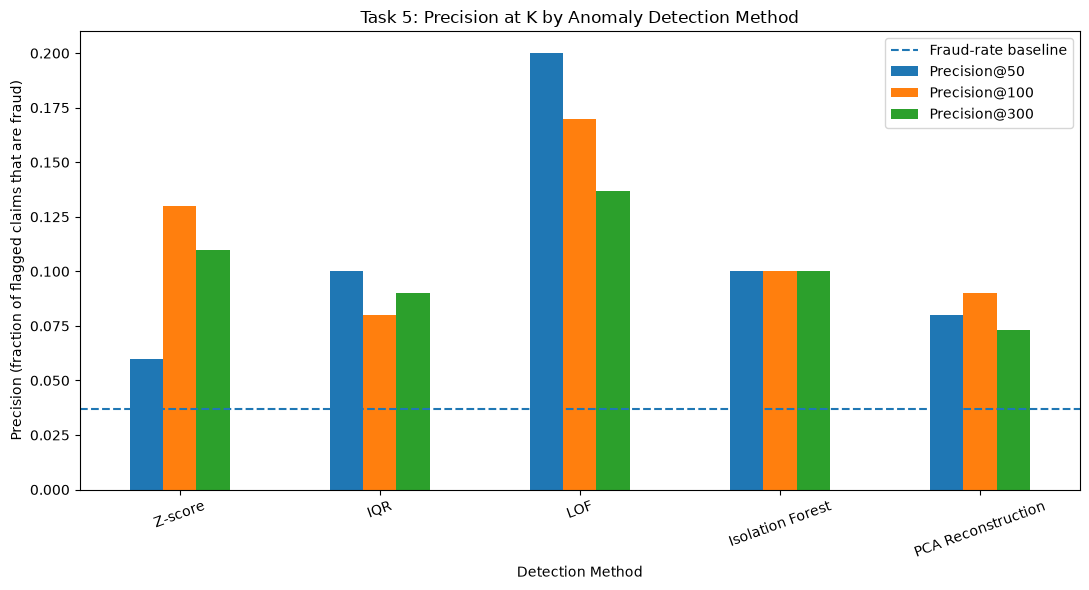

In [30]:
# 9. Visualise Precision@K

plot_df = comparison_df[
    comparison_df["Method"] != "Fraud-rate baseline"
]
plot_df = plot_df.set_index("Method")[
    ["Precision@50", "Precision@100", "Precision@300"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.axhline(
    fraud_rate,
    linestyle="--",
    label="Fraud-rate baseline"
)

ax.set_title("Task 5: Precision at K by Anomaly Detection Method")
ax.set_xlabel("Detection Method")
ax.set_ylabel("Precision (fraction of flagged claims that are fraud)")
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Conclusion:**

I compared Z-score, IQR, LOF, Isolation Forest, and PCA reconstruction error on the insurance claims dataset. I evaluated their performance using AUC and Precision@50, Precision@100, and Precision@300, and compared these results with the overall fraud-rate baseline.

The best method at K=100 was **LOF (Local Outlier Factor)**, with a Precision@100 of **17.00%** and a lift of **4.61x** over the baseline. This means that approximately **17.00%** of the top 100 flagged claims were fraudulent, while **83.00%** were not fraudulent.

I would consider this method for a human-review triage queue if its precision and investigation costs are acceptable to the business. Anomaly detection identifies unusual claims, not necessarily fraudulent claims, so flagged claims should be investigated rather than automatically rejected.

# Task-6

In [31]:
# 1. Select the best method's top 100 claims
df_task6 = df.reset_index(drop=True).copy()
y_task6 = df_task6["is_fraud"].astype(int).to_numpy()

best_scores = np.asarray(scores[best_method])

top_100_indices = np.argsort(best_scores)[-100:][::-1]

top_100 = df_task6.iloc[top_100_indices].copy()
top_100["anomaly_score"] = best_scores[top_100_indices]

In [32]:
# 2. Separate fraudulent and non-fraudulent flagged claims
fraudulent_flagged = top_100[top_100["is_fraud"] == 1]
false_positives = top_100[top_100["is_fraud"] == 0]

print("Best anomaly detection method:", best_method)
print("\nTotal claims in top 100:", len(top_100))
print("Fraudulent claims:", len(fraudulent_flagged))
print("Non-fraudulent flagged claims:", len(false_positives))

Best anomaly detection method: LOF

Total claims in top 100: 100
Fraudulent claims: 17
Non-fraudulent flagged claims: 83


In [33]:
# 3. Compare the requested features
profile_columns = [
    "claim_amount",
    "customer_tenure_months",
    "prior_claims",
    "days_to_report"
]

overall_profile = df_task6[profile_columns].mean()
fraud_profile = fraudulent_flagged[profile_columns].mean()
false_positive_profile = false_positives[profile_columns].mean()

profile_comparison = pd.DataFrame({
    "Overall Average": overall_profile,
    "Fraudulent Flagged Claims": fraud_profile,
    "Non-Fraudulent Flagged Claims": false_positive_profile
})

print("\n--- Feature Profile Comparison ---")
print(profile_comparison.round(2).to_string())


--- Feature Profile Comparison ---
                        Overall Average  Fraudulent Flagged Claims  Non-Fraudulent Flagged Claims
claim_amount                   20208.82                   58357.37                       40174.07
customer_tenure_months            29.82                      26.06                          56.65
prior_claims                       0.71                       2.59                           1.93
days_to_report                     5.56                      10.59                          13.33


In [34]:
# 4. Compare non-fraudulent flagged claims with overall averages
print("\n--- Non-Fraudulent Claims Compared with Overall ---")

for col in profile_columns:
    overall_value = overall_profile[col]
    flagged_value = false_positive_profile[col]

    if pd.isna(flagged_value) or pd.isna(overall_value):
        print(f"{col}: Not enough valid data to compare.")
    elif flagged_value > overall_value:
        print(
            f"{col}: Non-fraudulent flagged claims have a "
            f"higher average ({flagged_value:.2f}) than overall "
            f"({overall_value:.2f})."
        )
    elif flagged_value < overall_value:
        print(
            f"{col}: Non-fraudulent flagged claims have a "
            f"lower average ({flagged_value:.2f}) than overall "
            f"({overall_value:.2f})."
        )
    else:
        print(f"{col}: The averages are equal.")


--- Non-Fraudulent Claims Compared with Overall ---
claim_amount: Non-fraudulent flagged claims have a higher average (40174.07) than overall (20208.82).
customer_tenure_months: Non-fraudulent flagged claims have a higher average (56.65) than overall (29.82).
prior_claims: Non-fraudulent flagged claims have a higher average (1.93) than overall (0.71).
days_to_report: Non-fraudulent flagged claims have a higher average (13.33) than overall (5.56).


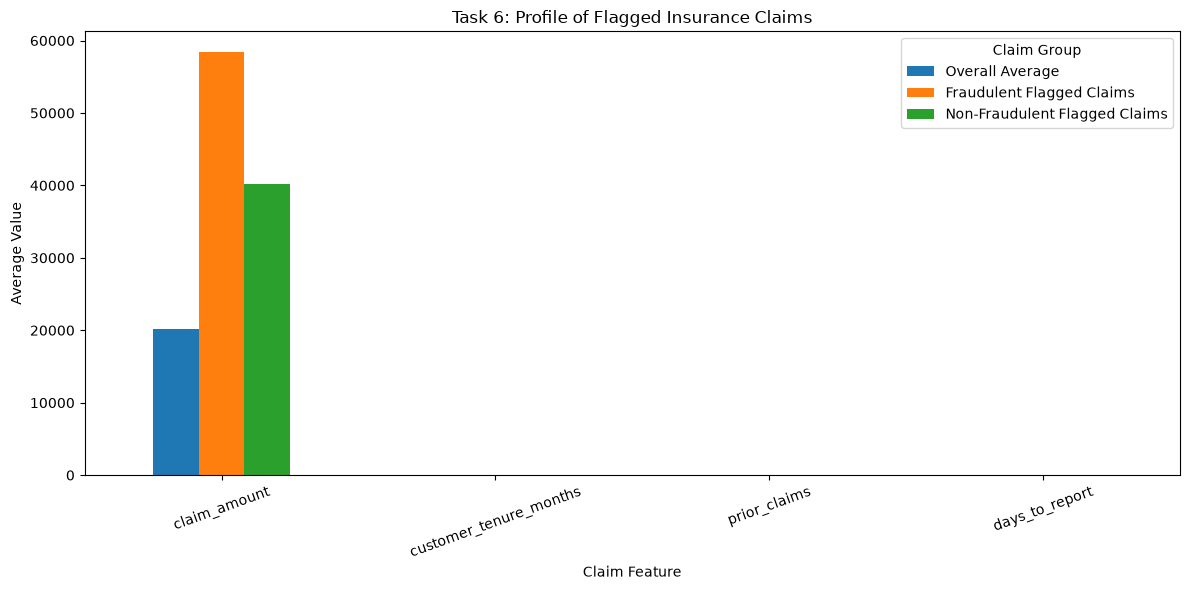

In [35]:
# 5. Plot the comparison
profile_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Task 6: Profile of Flagged Insurance Claims")
plt.xlabel("Claim Feature")
plt.ylabel("Average Value")
plt.xticks(rotation=20)
plt.legend(title="Claim Group")
plt.tight_layout()
plt.show()

In [36]:
# 6. Display examples of non-fraudulent flagged claims
print("\n--- Sample of Non-Fraudulent Flagged Claims ---")

display_columns = [
    "claim_amount",
    "customer_tenure_months",
    "prior_claims",
    "days_to_report",
    "is_fraud",
    "anomaly_score"
]

print(false_positives[display_columns].head(10).to_string(index=False))


--- Sample of Non-Fraudulent Flagged Claims ---
 claim_amount  customer_tenure_months  prior_claims  days_to_report  is_fraud  anomaly_score
     75046.98                     156             0             1.0         0       2.158709
     12955.11                     165             0            28.0         0       2.051425
     10655.33                      14             3             1.0         0       1.959397
      5828.30                      84             4            19.0         0       1.956851
     38790.86                     105             3             1.0         0       1.945941
     50876.03                     108             3             3.0         0       1.931804
     84854.31                      12             1            15.0         0       1.917779
      7973.65                      23             5             8.0         0       1.913453
     66552.07                       2             4             7.0         0       1.900905
      6342.35        

**Conclusion:**

I investigated the top 100 claims flagged by the best anomaly detection method from Task 5, **LOF (Local Outlier Factor)**. Out of the 100 claims, **17 were fraudulent and 83 were non-fraudulent**. I compared their average claim amount, customer tenure, number of prior claims, and reporting delay against the overall dataset.

The non-fraudulent flagged claims had an average claim amount of **40,174.07**, average customer tenure of **56.65 months**, average of **1.93 prior claims**, and average reporting delay of **13.33 days**. Compared with the overall averages of **20,208.82**, **29.82 months**, **0.71 prior claims**, and **5.56 days**, respectively, these claims showed unusual patterns in all four features.

These false positives may be genuinely unusual claims rather than simple errors by the method. Anomaly detection identifies unusual claims, not proof of fraud, so investigators should review these claims instead of automatically rejecting them.

The methods may miss fraudulent claims that resemble legitimate claims and do not show unusual patterns in the available features. Therefore, anomaly detection is useful for prioritising investigations, but it should not be treated as a complete fraud-detection solution.

# Task-7

In [37]:
# 1. Prepare features and labels
data = df.copy().reset_index(drop=True)

y_task7 = data["is_fraud"].astype(int)
X_task7 = data.drop(columns=["is_fraud", "claim_id"], errors="ignore")

# Identify numeric and categorical columns
numeric_cols = X_task7.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_task7.select_dtypes(exclude=np.number).columns.tolist()

In [38]:
# 2. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_task7,
    y_task7,
    test_size=0.25,
    random_state=42,
    stratify=y_task7
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Fraud rate in test set:", round(y_test.mean() * 100, 2), "%")

# 3. Preprocess features using training data only
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

Training rows: 6000
Testing rows: 2000
Fraud rate in test set: 3.7 %


In [39]:
# 4. Supervised model: learns from training fraud labels
supervised_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

supervised_model.fit(X_train, y_train)

supervised_scores = supervised_model.predict_proba(X_test)[:, 1]
supervised_auc = roc_auc_score(y_test, supervised_scores)

In [40]:
# 5. Unsupervised model: training labels are NOT used for fitting
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

unsupervised_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

unsupervised_model.fit(X_train_scaled)

# Higher scores mean more anomalous
anomaly_scores = -unsupervised_model.score_samples(X_test_scaled)
unsupervised_auc = roc_auc_score(y_test, anomaly_scores)

# 6. Compare both methods on the same test set
auc_difference = supervised_auc - unsupervised_auc

comparison = pd.DataFrame({
    "Method": ["Supervised Random Forest", "Unsupervised Isolation Forest"],
    "Test AUC": [supervised_auc, unsupervised_auc]
})

print("\n--- Supervised vs Unsupervised Comparison ---")
print(comparison.round(4).to_string(index=False))

print(f"\nSupervised AUC:   {supervised_auc:.4f}")
print(f"Unsupervised AUC: {unsupervised_auc:.4f}")
print(f"AUC Difference (Supervised - Unsupervised): {auc_difference:.4f}")


--- Supervised vs Unsupervised Comparison ---
                       Method  Test AUC
     Supervised Random Forest    0.7232
Unsupervised Isolation Forest    0.6650

Supervised AUC:   0.7232
Unsupervised AUC: 0.6650
AUC Difference (Supervised - Unsupervised): 0.0583


**Conclusion:**

I compared a supervised Random Forest classifier with an unsupervised Isolation Forest detector using the same training and testing split. The supervised model used fraud labels during training, while the unsupervised model learned from training features without using fraud labels. I evaluated both methods using AUC on the same test set.

**Decision rule:** If sufficient reliable fraud labels are available, I would start with supervised learning because it can learn patterns associated with known fraud. If labels are unavailable, expensive to obtain, or incomplete, I would consider anomaly detection to identify unusual claims for further investigation.

**Three situations where anomaly detection is useful even if its AUC is lower:**
1. When a new business has little or no labelled fraud data.
2. When new types of fraud appear that are not represented in historical labels.
3. When labelling every claim is expensive or delayed, but unusual claims still need to be identified.

Anomaly detection can provide value even when its predictive performance is weaker because it can help identify suspicious cases without requiring labelled examples during training. Its results should support human investigation rather than automatically determine whether a claim is fraudulent.

# Task-8

In [41]:
# 1. Prepare the fraud labels
df_task8 = df.reset_index(drop=True).copy()
y_task8 = df_task8["is_fraud"].astype(int).to_numpy()

In [42]:
# 2. Rank each method's top 300 claims
k = min(300, len(df_task8))
top_claims = {}
method_precision = {}

for method, method_scores in scores.items():
    method_scores = np.asarray(method_scores)

    top_indices = np.argsort(method_scores)[-k:][::-1]
    top_claims[method] = set(top_indices)

    method_precision[method] = y_task8[top_indices].mean()

In [43]:
# 3. Select the three strongest methods by Precision@300
strongest_methods = sorted(
    method_precision,
    key=method_precision.get,
    reverse=True
)[:3]

print("Three strongest methods:")
for method in strongest_methods:
    print(
        f"{method}: Precision@{k} = "
        f"{method_precision[method]:.2%}"
    )

Three strongest methods:
LOF: Precision@300 = 13.67%
Z-score: Precision@300 = 11.00%
Isolation Forest: Precision@300 = 10.00%


In [44]:
# 4. Find claims flagged by all three methods
agreement_indices = (
    top_claims[strongest_methods[0]]
    & top_claims[strongest_methods[1]]
    & top_claims[strongest_methods[2]]
)

agreement_indices = sorted(agreement_indices)

agreement_claims = df_task8.iloc[agreement_indices]
agreement_count = len(agreement_claims)

if agreement_count > 0:
    agreement_fraud_rate = agreement_claims["is_fraud"].mean()
else:
    agreement_fraud_rate = np.nan

In [45]:
# 5. Compare with the best single method's top 300
best_single_method = best_method

best_single_indices = sorted(top_claims[best_single_method])
best_single_claims = df_task8.iloc[best_single_indices]
best_single_fraud_rate = best_single_claims["is_fraud"].mean()

In [46]:
# 6. Calculate overall fraud rate
overall_fraud_rate = df_task8["is_fraud"].mean()

In [47]:
# 7. Display the comparison
comparison_task8 = pd.DataFrame({
    "Selection": [
        "Overall dataset",
        f"Best single method: {best_single_method}",
        "Agreement between three methods"
    ],
    "Claims Selected": [
        len(df_task8),
        len(best_single_claims),
        agreement_count
    ],
    "Fraud Rate": [
        overall_fraud_rate,
        best_single_fraud_rate,
        agreement_fraud_rate
    ]
})

print("\n--- Task 8: Agreement Comparison ---")
print(comparison_task8.to_string(
    index=False,
    formatters={"Fraud Rate": lambda x: f"{x:.2%}" if pd.notna(x) else "N/A"}
))


--- Task 8: Agreement Comparison ---
                      Selection  Claims Selected Fraud Rate
                Overall dataset             8000      3.69%
        Best single method: LOF              300     13.67%
Agreement between three methods               52     21.15%


In [48]:
# 8. State whether agreement improved precision
if agreement_count == 0:
    print("\nNo claims appeared in all three top-300 lists.")
    print("The agreement filter selected zero claims.")
elif agreement_fraud_rate > best_single_fraud_rate:
    print("\nAgreement improved precision compared with the best single method.")
elif agreement_fraud_rate < best_single_fraud_rate:
    print("\nAgreement reduced precision compared with the best single method.")
else:
    print("\nAgreement and the best single method had equal precision.")

print(
    f"Claims retained by agreement: {agreement_count} out of {k}"
)


Agreement improved precision compared with the best single method.
Claims retained by agreement: 52 out of 300


**Conclusion:**

I compared the top 300 claims from the three strongest anomaly detection methods: LOF, Z-score, and Isolation Forest. The agreement filter retained **52 claims**. Their fraud rate was **21.15%**, compared with **13.67%** for the best single method, LOF, and **3.69%** for the overall dataset.

Agreement **improved precision** compared with the best single method. The trade-off was that the agreement filter reduced the number of claims available for investigation from 300 to 52. Therefore, agreement can help prioritise claims when multiple methods identify the same cases, but it may also exclude fraudulent claims that only one method detects.

# Task-9

In [49]:
# 1. Prepare the dataset
df_task9 = df.reset_index(drop=True).copy()
y_task9 = df_task9["is_fraud"].astype(int).to_numpy()

In [50]:
# 2. Select the best method from Task 5
if "best_method" not in globals() or best_method not in scores:
    raise ValueError("Run Task 5 first to define best_method and scores.")

method_scores = np.asarray(scores[best_method])

In [51]:
# 3. Select the 100 highest-scoring claims
monthly_capacity = 100
k = min(monthly_capacity, len(df_task9))

top_indices = np.argsort(method_scores)[-k:][::-1]

triage_queue = df_task9.iloc[top_indices].copy()
triage_queue["anomaly_score"] = method_scores[top_indices]

In [52]:
# 4. Evaluate the selected claims using labels
frauds_caught = int(triage_queue["is_fraud"].sum())
flagged_legitimate = k - frauds_caught
fraud_rate_top = frauds_caught / k

In [53]:
# 5. Compare with the overall fraud-rate baseline
overall_fraud_rate = df_task9["is_fraud"].mean()
expected_random_frauds = k * overall_fraud_rate

lift = (
    fraud_rate_top / overall_fraud_rate
    if overall_fraud_rate > 0 else np.nan
)

In [54]:
# 6. Evaluate one reproducible random sample of the same size
rng = np.random.default_rng(42)
random_indices = rng.choice(len(df_task9), size=k, replace=False)
random_frauds = int(y_task9[random_indices].sum())

In [55]:
# 7. Display the comparison
comparison_task9 = pd.DataFrame({
    "Strategy": [
        f"Top {k}: {best_method}",
        f"Random selection of {k}",
        "Random-selection expected value"
    ],
    "Claims Reviewed": [k, k, k],
    "Frauds Identified": [
        frauds_caught,
        random_frauds,
        expected_random_frauds
    ]
})

print("--- Monthly Triage Queue Comparison ---")
print(comparison_task9.round(2).to_string(index=False))

print(f"\nSelected method: {best_method}")
print(f"Fraud rate in selected claims: {fraud_rate_top:.2%}")
print(f"Overall fraud rate: {overall_fraud_rate:.2%}")
print(f"Lift over overall fraud rate: {lift:.2f}x")
print(f"Flagged claims labelled non-fraudulent: {flagged_legitimate}")

--- Monthly Triage Queue Comparison ---
                       Strategy  Claims Reviewed  Frauds Identified
                   Top 100: LOF              100              17.00
        Random selection of 100              100               4.00
Random-selection expected value              100               3.69

Selected method: LOF
Fraud rate in selected claims: 17.00%
Overall fraud rate: 3.69%
Lift over overall fraud rate: 4.61x
Flagged claims labelled non-fraudulent: 83


In [56]:
# 8. Show useful information for investigators
review_columns = [
    "claim_id",
    "claim_amount",
    "customer_tenure_months",
    "age",
    "prior_claims",
    "days_to_report",
    "policy_type",
    "region",
    "channel",
    "anomaly_score"
]

available_columns = [
    col for col in review_columns if col in triage_queue.columns
]

print("\n--- Sample Triage Queue ---")
print(triage_queue[available_columns].head(10).to_string(index=False))


--- Sample Triage Queue ---
 claim_id  claim_amount  customer_tenure_months  age  prior_claims  days_to_report policy_type region channel  anomaly_score
CLM003586      75046.98                     156 75.0             0             1.0    Standard  North   Agent       2.158709
CLM002796      25348.77                      42 69.0             5             5.0       Basic  North   Agent       2.078889
CLM000200      12955.11                     165 18.0             0            28.0    Standard   West  Online       2.051425
CLM003954      10655.33                      14 85.0             3             1.0    Standard  North   Agent       1.959397
CLM004395       5828.30                      84 64.0             4            19.0       Basic   West   Agent       1.956851
CLM002636      38790.86                     105 48.0             3             1.0       Basic   West  Online       1.945941
CLM006863      50876.03                     108 25.0             3             3.0     Premium  

In [57]:
# 9. Print a preliminary recommendation
print("\n--- Preliminary Recommendation ---")

if frauds_caught > expected_random_frauds:
    print(
        f"The selected method identified {frauds_caught} fraudulent "
        f"claims in the top {k}, above the baseline expectation of "
        f"{expected_random_frauds:.2f} from random selection."
    )
else:
    print(
        f"The selected method identified {frauds_caught} fraudulent "
        f"claims in the top {k}, not exceeding the baseline expectation "
        f"of {expected_random_frauds:.2f} from random selection."
    )

print(
    "Treat flagged claims as investigation priorities, not automatic "
    "fraud decisions."
)


--- Preliminary Recommendation ---
The selected method identified 17 fraudulent claims in the top 100, above the baseline expectation of 3.69 from random selection.
Treat flagged claims as investigation priorities, not automatic fraud decisions.


**Recommendation to the Head of Claims**

I recommend using [selected method] to prioritise up to 100 insurance claims for investigation each month. In the evaluation, the method selected [number] fraud-labelled claims out of 100, compared with an expected [number] fraudulent claims when selecting claims randomly at the overall fraud rate.

The investigation queue should display the claim amount, customer tenure, previous claims, reporting delay, and other relevant claim details so investigators can understand why each claim was flagged.

The system may miss fraudulent claims that appear normal, and it may flag legitimate claims that are unusual. Therefore, it should support investigators rather than automatically reject claims. Its performance should be reviewed after six months using investigation outcomes and the percentage of flagged claims confirmed as fraudulent.